## 이미지 전이학습: 연습문제 정답


In [1]:
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision.datasets.utils import download_and_extract_archive
from torchvision.models import resnet18, ResNet18_Weights

SEED = 42
torch.manual_seed(SEED)


### 데이터 준비

분류 대상을 개·고양이로 바꾼다. 사전학습 가중치에 맞는 기본 전처리를 사용한다.


In [2]:
data_root = Path("image_data")
cats_root = data_root / "cats_and_dogs_filtered"
if not cats_root.exists():
    download_and_extract_archive(
        "https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip",
        download_root=str(data_root),
    )

weights = ResNet18_Weights.DEFAULT
image_transform = weights.transforms()

cats_source_train = ImageFolder(cats_root / "train")
cats_source_holdout = ImageFolder(cats_root / "validation")
cats_train_images = ImageFolder(cats_root / "train", transform=image_transform)
cats_holdout_images = ImageFolder(cats_root / "validation", transform=image_transform)
cats_classes = cats_source_train.classes

print("클래스 번호:", cats_source_train.class_to_idx)
print("학습용 / 검증·테스트 분리용 이미지 수:", len(cats_source_train), len(cats_source_holdout))


클래스 번호: {'cats': 0, 'dogs': 1}
학습용 / 검증·테스트 분리용 이미지 수: 2000 1000


### 학습·검증·테스트 분리

`train`의 2,000장은 학습에 사용하고, `validation`의 1,000장은 클래스 비율을 유지하며 검증 500장과 테스트 500장으로 나눈다.


In [3]:
holdout_targets = np.array(cats_source_holdout.targets)
val_idx, test_idx = train_test_split(
    np.arange(len(cats_source_holdout)), test_size=0.5,
    stratify=holdout_targets, random_state=SEED,
)

raw_val = DataLoader(Subset(cats_holdout_images, val_idx), batch_size=32)
raw_test = DataLoader(Subset(cats_holdout_images, test_idx), batch_size=32)

def make_image_train_loader():
    # 두 방식에서 같은 순서로 학습 이미지를 섞는다.
    return DataLoader(
        cats_train_images, batch_size=32, shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )

split_targets = {
    "train": np.array(cats_source_train.targets),
    "validation": holdout_targets[val_idx],
    "test": holdout_targets[test_idx],
}
display(pd.DataFrame({
    name: np.bincount(labels, minlength=len(cats_classes))
    for name, labels in split_targets.items()
}, index=cats_classes))


,train,validation,test
cats,1000,250,250
dogs,1000,250,250


### 사전학습 모델과 분류 헤드 준비


In [4]:
torch.manual_seed(SEED)
initial_model = resnet18(weights=weights)
initial_model.fc = nn.Linear(initial_model.fc.in_features, len(cats_classes))


### 공통 학습·평가 함수


In [5]:
def train_one_epoch(model, loader, optimizer):
    model.train()

    loss_sum, correct, count = 0.0, 0, 0
    for inputs, labels in loader:
        logits = model(inputs)
        loss = nn.functional.cross_entropy(logits, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        count += len(labels)

    return loss_sum / count, correct / count


In [6]:
@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for inputs, labels in loader:
        logits = model(inputs)
        loss_sum += nn.functional.cross_entropy(logits, labels).item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        count += len(labels)

    return loss_sum / count, correct / count


In [7]:
def fit_classifier(model, train_loader, val_loader, epochs, lr):
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)

    history = []
    best_loss, best_state = float("inf"), None

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_acc = evaluate_classifier(model, val_loader)
        history.append({"epoch": epoch + 1, "train_loss": train_loss,
                        "val_loss": val_loss, "train_accuracy": train_acc, "val_accuracy": val_acc})

        if val_loss < best_loss:
            best_loss, best_state = val_loss, deepcopy(model.state_dict())

        print(f"epoch={epoch+1} train_loss={train_loss:.3f} val_loss={val_loss:.3f} val_acc={val_acc:.3f}")

    model.load_state_dict(best_state)
    model.eval()
    return pd.DataFrame(history)


## 두 학습 방식 비교

두 모델은 같은 초기 가중치와 데이터 순서로 시작한다. 학습 범위와 학습률을 다음과 같이 설정한다.

| 방식 | 학습 범위 | 학습률 | 에포크 수 |
| --- | --- | --- | --- |
| 특징 추출 | 분류 헤드 | 0.001 | 5 |
| 전체 미세 조정 | 백본과 분류 헤드 전체 | 0.0001 | 5 |

### 특징 추출 방식


In [8]:
head_model = deepcopy(initial_model)
head_model.requires_grad_(False)
head_model.fc.requires_grad_(True)

HEAD_EPOCHS = 5
torch.manual_seed(SEED)
feature_history = fit_classifier(
    head_model, make_image_train_loader(), raw_val,
    epochs=HEAD_EPOCHS, lr=0.001,
)


epoch=1 train_loss=0.331 val_loss=0.126 val_acc=0.972


epoch=2 train_loss=0.144 val_loss=0.097 val_acc=0.970


epoch=3 train_loss=0.119 val_loss=0.100 val_acc=0.956


epoch=4 train_loss=0.109 val_loss=0.059 val_acc=0.982


epoch=5 train_loss=0.089 val_loss=0.054 val_acc=0.986


### 전체 미세 조정 방식


In [9]:
fine_model = deepcopy(initial_model)
fine_model.requires_grad_(True)

FINE_TUNE_EPOCHS = 5
torch.manual_seed(SEED)
fine_history = fit_classifier(
    fine_model, make_image_train_loader(), raw_val,
    epochs=FINE_TUNE_EPOCHS, lr=0.0001,
)


epoch=1 train_loss=0.129 val_loss=0.048 val_acc=0.982


epoch=2 train_loss=0.022 val_loss=0.037 val_acc=0.990


epoch=3 train_loss=0.016 val_loss=0.045 val_acc=0.982


epoch=4 train_loss=0.004 val_loss=0.034 val_acc=0.986


epoch=5 train_loss=0.003 val_loss=0.042 val_acc=0.984


### 검증 결과 비교

각 방식에서 검증 손실이 가장 작았던 가중치로 비교하고, 검증 손실이 낮은 모델을 선택한다.


In [10]:
transfer_models = {"head_only": head_model, "fine_tuned": fine_model}
transfer_histories = {"head_only": feature_history, "fine_tuned": fine_history}

rows = []
for name, candidate in transfer_models.items():
    loss, accuracy = evaluate_classifier(candidate, raw_val)
    history = transfer_histories[name]
    best_epoch = int(history.loc[history["val_loss"].idxmin(), "epoch"])
    rows.append({
        "model": name, "best_epoch": best_epoch,
        "val_loss": loss, "val_accuracy": accuracy,
    })

transfer_results = pd.DataFrame(rows).sort_values("val_loss").reset_index(drop=True)
display(transfer_results)

selected_transfer = transfer_results.iloc[0]["model"]
selected_model = transfer_models[selected_transfer]
print("검증 손실로 선택한 모델:", selected_transfer)


,model,best_epoch,val_loss,val_accuracy
0,fine_tuned,4,0.034468,0.986
1,head_only,5,0.053706,0.986


검증 손실로 선택한 모델: fine_tuned


### 학습 곡선 비교


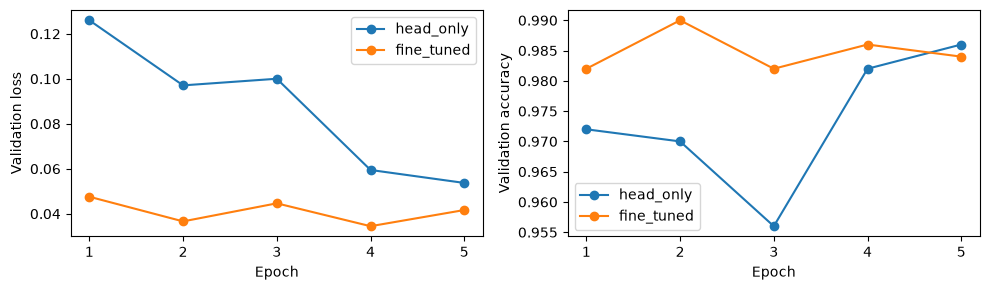

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for name, history in transfer_histories.items():
    axes[0].plot(history["epoch"], history["val_loss"], marker="o", label=name)
    axes[1].plot(history["epoch"], history["val_accuracy"], marker="o", label=name)

for ax, metric in zip(axes, ["Validation loss", "Validation accuracy"]):
    ax.set_xlabel("Epoch")
    ax.set_ylabel(metric)
    ax.set_xticks(range(1, HEAD_EPOCHS + 1))
    ax.legend()
plt.tight_layout()
plt.show()


### 최종 테스트


In [12]:
test_loss, test_accuracy = evaluate_classifier(selected_model, raw_test)
print("선택한 모델:", selected_transfer)
display(pd.DataFrame([{
    "model": selected_transfer, "test_loss": test_loss, "test_accuracy": test_accuracy,
}]))


선택한 모델: fine_tuned


,model,test_loss,test_accuracy
0,fine_tuned,0.06225,0.974
